In [1]:
import numpy as np
import torch

import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../src")))

from autoencoder import SINDyConvAE
from training import train_sindy_convae, save_model_and_params
from sindy_utils import library_size

from example_dg import get_dg_data, get_dg_loaders


[INFO] Global seed set to 42 (PyTorch, NumPy, Random)


In [2]:
# physical parameters
amplitude = 0.25
frequency = 5.0     

# spatial discretization
nx = 64
ny = 32
Lx = 2.0
Ly = 1.0

# temporal discretization
dt = 0.05
T = 100.0

# Dataset creation
train_d, val_d, test_d = get_dg_data(randomized=False,
                                     amplitude=amplitude, frequency=frequency, 
                                     Lx=Lx, Ly=Ly, nx=nx, ny=ny,
                                     T=T, dt=dt)


In [3]:
# ConvAE+SINDy parameters
params={}

# CAE structure
params['input_shape'] = (nx, ny, 2)
params['filter_widths'] = [16, 32]

# SINDy latent library
params['latent_dim'] = 1
params['poly_order'] = 3
params['include_sine'] = True
params['library_dim'] = library_size(params['latent_dim'], params['poly_order'], params['include_sine'])

# Loss penalties
params['loss_weights'] = {
    'decoder': 1.0,                     # Ricostruzione x
    'sindy_x': 1e-3,                    # Ricostruzione dx (tramite la dinamica latente)
    'sindy_z': 1e-3,                    # Consistenza latente dz/dt = Theta * Xi
    'sindy_reg': 1e-6        # Sparsità (L1) dei coefficienti SINDy
}

# Thresholding
params['sequential_thresholding'] = True
params['threshold_frequency'] = 100
params['coefficient_threshold'] = 1e-2

# Training
params['activation'] = 'tanh'
params['learning_rate'] = 1e-3
params['batch_size'] = 32
params['print_frequency'] = 20

params['max_epochs'] = 1001
params['refinement_epochs'] = 201


In [4]:
# Torch loaders
train_loader, val_loader, test_loader = get_dg_loaders(train_d, val_d, test_d, 
                                                       batch_size=params['batch_size'], 
                                                       channels_first=False,
                                                       train_shuffle=False,
                                                       include_time=False)

In [5]:
# Model
model = SINDyConvAE(params)

# Train of the model
history = train_sindy_convae(model, train_loader, val_loader, params)

# Save
save_model_and_params(model, params, folder_path="./saved", model_name="model_standard")



[INFO] SINDy Autoencoder Configuration:
  > Decoder weight:  1.00e+00
  > SINDy x weight:  1.00e-03
  > SINDy z weight:  1.00e-03
  > SINDy Reg (L1):  1.00e-06
[INFO] Computation norms on validation set...
[INFO] Validation X norm (MSE baseline): 2.4992e-02
[INFO] Validation dX norm (MSE baseline): 1.1170e-01

--- PHASE 1: TRAINING ---
[TRAIN] Epoch    0
  Train Loss: 2.5744e-02 ( Dec: 2.56e-02 | dX: 1.12e-01 | dZ: 1.77e-02 | Reg: 5.42e-01 )
  Valid Loss: 1.3186e-02 ( Dec: 1.31e-02 | dX: 1.16e-01 | dZ: 3.43e-03 )
  >> RATIO: Decoder: 0.5228 | SINDy: 1.0361
[TRAIN] Epoch   20
  Train Loss: 2.5598e-03 ( Dec: 1.96e-03 | dX: 5.38e-02 | dZ: 5.44e-01 | Reg: 4.85e-01 )
  Valid Loss: 2.0035e-03 ( Dec: 1.42e-03 | dX: 4.36e-02 | dZ: 5.38e-01 )
  >> RATIO: Decoder: 0.0569 | SINDy: 0.3899
[TRAIN] Epoch   40
  Train Loss: 2.5860e-04 ( Dec: 1.82e-04 | dX: 1.28e-02 | dZ: 6.32e-02 | Reg: 4.64e-01 )
  Valid Loss: 2.7717e-04 ( Dec: 2.02e-04 | dX: 1.29e-02 | dZ: 6.21e-02 )
  >> RATIO: Decoder: 0.0081 | 

In [6]:
# Analisi dei risultati finali
with torch.no_grad():
    # .detach() rimuove il tensore dal grafo dei gradienti
    final_xi = (model.sindy_coeffs * model.sindy_mask).detach().cpu().numpy()

print("Xi final:")
print(np.round(final_xi, 4)) 

active_mask = np.abs(final_xi) > 0
print(f"Active coefficients: {np.sum(active_mask)}")

Xi final:
[[ 0.    ]
 [ 0.4216]
 [ 0.    ]
 [-0.    ]
 [-0.4252]]
Active coefficients: 2


In [5]:
import torch
import pickle
import numpy as np

# 1. Carica i parametri della struttura (architettura)
with open('./saved/model_standard_params.pkl', 'rb') as f:
    params = pickle.load(f)

# 2. Istanzia il modello
# Nota: Devi aver importato la classe SINDyAutoencoder definita nel tuo script
model = SINDyConvAE(params) 

# 3. Carica i pesi di PyTorch (Weights & Buffers)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.load_state_dict(torch.load('./saved/model_standard.pth', map_location=device))
model.eval() # Imposta in modalità valutazione

# 4. Carica i coefficienti SINDy (la "fisica" scoperta)
final_xi = np.load('./saved/model_standard_coefficients.npy')

print("Caricamento completato con successo!")
print(f"Forma dei coefficienti SINDy: {final_xi.shape}")

Caricamento completato con successo!
Forma dei coefficienti SINDy: (5, 1)


std:  0.025628828


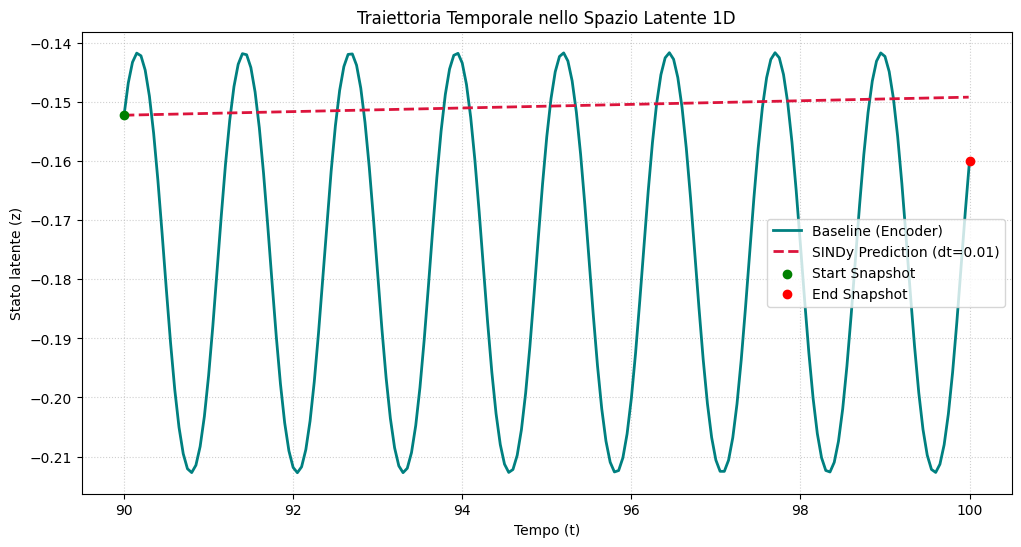

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from sindy_utils import sindy_simulate

def evaluate_and_plot_latent_1d(model, test_loader, Xi, poly_order, include_sine, device='cpu'):
    model.eval()
    z_list = []
    
    # 1. Estrazione traiettoria reale dall'Encoder
    with torch.no_grad():
        for batch in test_loader:
            # Il loader restituisce (x, dx), prendiamo x (batch[0])
            x = batch[0].to(device)
            z = model.encode(x)
            z_list.append(z.cpu().numpy())
    
    # Concateniamo e forziamo a 1D
    z_real = np.concatenate(z_list).flatten()
    n_samples = len(z_real)
    print("std: ", np.sqrt(np.var(z_real, ddof=1)))
    # 2. Generazione asse temporale (90, 100)
    t_axis = np.linspace(90, 100, num=n_samples)
    
    # 3. Simulazione SINDy (dt=0.01)
    # Creiamo un nuovo asse temporale con il passo specifico richiesto
    dt = 0.01
    t_sim = np.arange(90, 100, dt)
    z0 = np.array([z_real[0]]) # Punto iniziale come array per odeint
    
    # Simulazione usando la tua funzione sindy_simulate
    z_sindy = sindy_simulate(z0, t_sim, Xi, poly_order, include_sine)
    
    # 4. Visualizzazione
    plt.figure(figsize=(12, 6))
    
    # Baseline dall'Encoder
    plt.plot(t_axis, z_real, color='teal', label='Baseline (Encoder)', linewidth=2)
    
    # Evoluzione predetta da SINDy
    plt.plot(t_sim, z_sindy, color='crimson', linestyle='--', label=f'SINDy Prediction (dt={dt})', linewidth=2)
    
    # Punti di controllo
    plt.scatter(90, z_real[0], color='green', zorder=5, label='Start Snapshot')
    plt.scatter(100, z_real[-1], color='red', zorder=5, label='End Snapshot')
    
    plt.title('Traiettoria Temporale nello Spazio Latente 1D')
    plt.xlabel('Tempo (t)')
    plt.ylabel('Stato latente (z)')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()

# --- ESECUZIONE ---
# Assicurati che Xi sia un array numpy estratto dal modello:
# Xi = model.Xi.detach().cpu().numpy()

evaluate_and_plot_latent_1d(
    model, 
    test_loader, 
    Xi=final_xi, 
    poly_order=params['poly_order'],
    include_sine=params['include_sine']
)

In [6]:
# Torch loaders
_, _, test_loader = get_dg_loaders(train_d, val_d, test_d, 
                                   batch_size=params['batch_size'], 
                                   channels_first=False,
                                   train_shuffle=False,
                                   include_time=True)

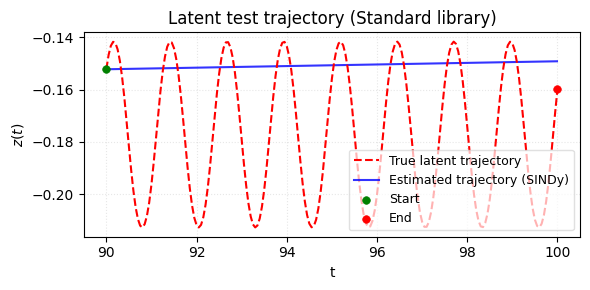

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator  # <--- Aggiunto per gestire i tick
from sindy_utils import sindy_simulate

def evaluate_and_plot_latent_1d(model, test_loader, Xi, poly_order, include_sine, device='cpu'):
    # =======================
    # STYLE CONFIGURATION
    # =======================
    plt.rcdefaults()
    
    model.eval()
    z_list = []
    
    # 1. Estrazione traiettoria reale dall'Encoder
    with torch.no_grad():
        for batch in test_loader:
            x = batch[0].to(device)
            z = model.encode(x)
            z_list.append(z.cpu().numpy())
    
    z_real = np.concatenate(z_list).flatten()
    n_samples = len(z_real)
    
    # 2. Generazione asse temporale
    t_axis = np.linspace(90, 100, num=n_samples)
    
    # 3. Simulazione SINDy
    dt = 0.01
    t_sim = np.arange(90, 100, dt)
    z0 = np.array([z_real[0]]) 
    
    z_sindy = sindy_simulate(z0, t_sim, Xi, poly_order, include_sine)
    
    # =======================
    # PLOTTING (Coherent Style)
    # =======================
    fig, ax = plt.subplots(figsize=(6, 3)) 
    
    # True Trajectory (Red Dashed)
    ax.plot(t_axis, z_real, linestyle='--',
            color='red', lw=1.5, 
            label='True latent trajectory', zorder=3)
    
    # Estimated Trajectory (Blue Solid)
    ax.plot(t_sim, z_sindy, 
            color='blue', alpha=0.8, lw=1.5, 
            label='Estimated trajectory (SINDy)', zorder=2)
    
    # Start / End Points
    ax.scatter(t_axis[0], z_real[0], 
               color='green', s=30, linewidths=0.5,
               zorder=3, label='Start')
    ax.scatter(t_axis[-1], z_real[-1], 
               color='red', s=30, linewidths=0.5,
               zorder=3, label='End')
    
    # --- GESTIONE TICK ASSE Y ---
    # nbins=5 limita il numero di tick per rendere il plot più arioso
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, prune='both')) 
    
    # Estetica assi
    ax.set_title('Latent test trajectory (Standard library)', fontsize=12)
    ax.set_xlabel('t', fontsize=10)
    ax.set_ylabel('$z(t)$', fontsize=10)
    
    # Griglia debole
    ax.grid(True, linestyle=':', alpha=0.3)
    
    # Legenda con background semitrasparente e contorno
    ax.legend(
        fontsize=9, 
        loc='lower right',
        frameon=True,
        framealpha=0.7,
        facecolor='white',
        edgecolor='lightgray',
        fancybox=True
    )
    
    plt.tight_layout()
    plt.show()


evaluate_and_plot_latent_1d(model, test_loader, Xi=final_xi, poly_order=params['poly_order'], include_sine=params['include_sine'])

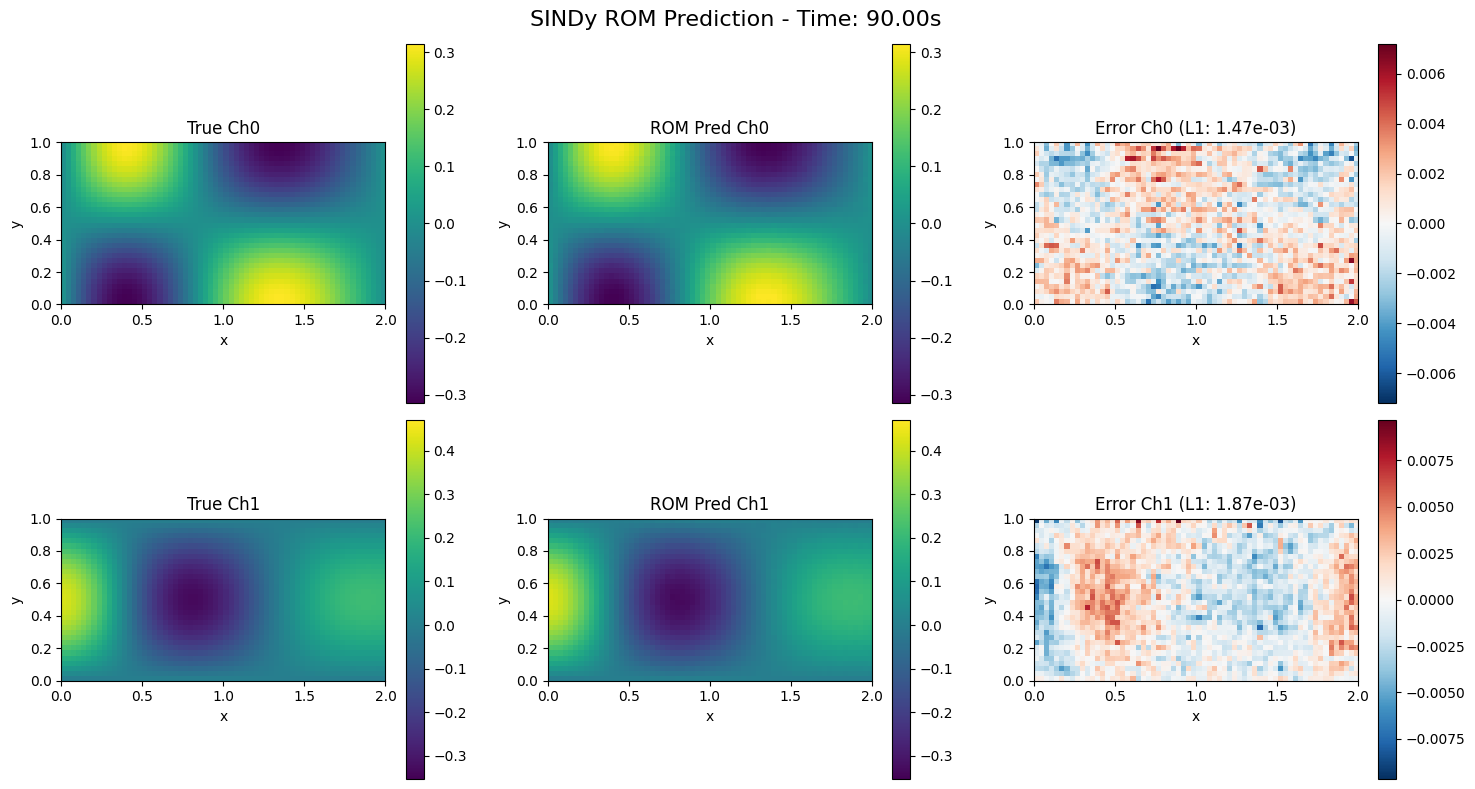

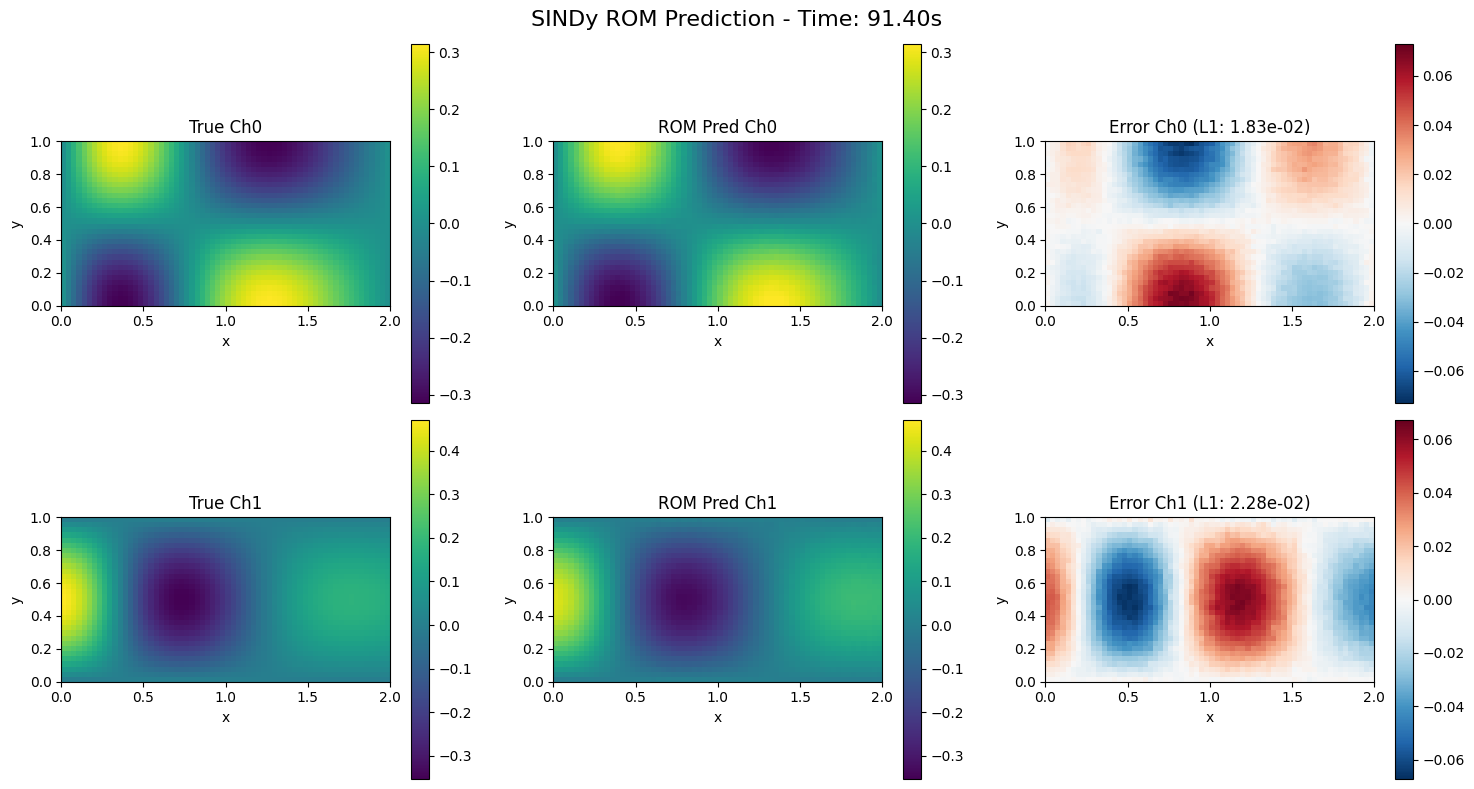

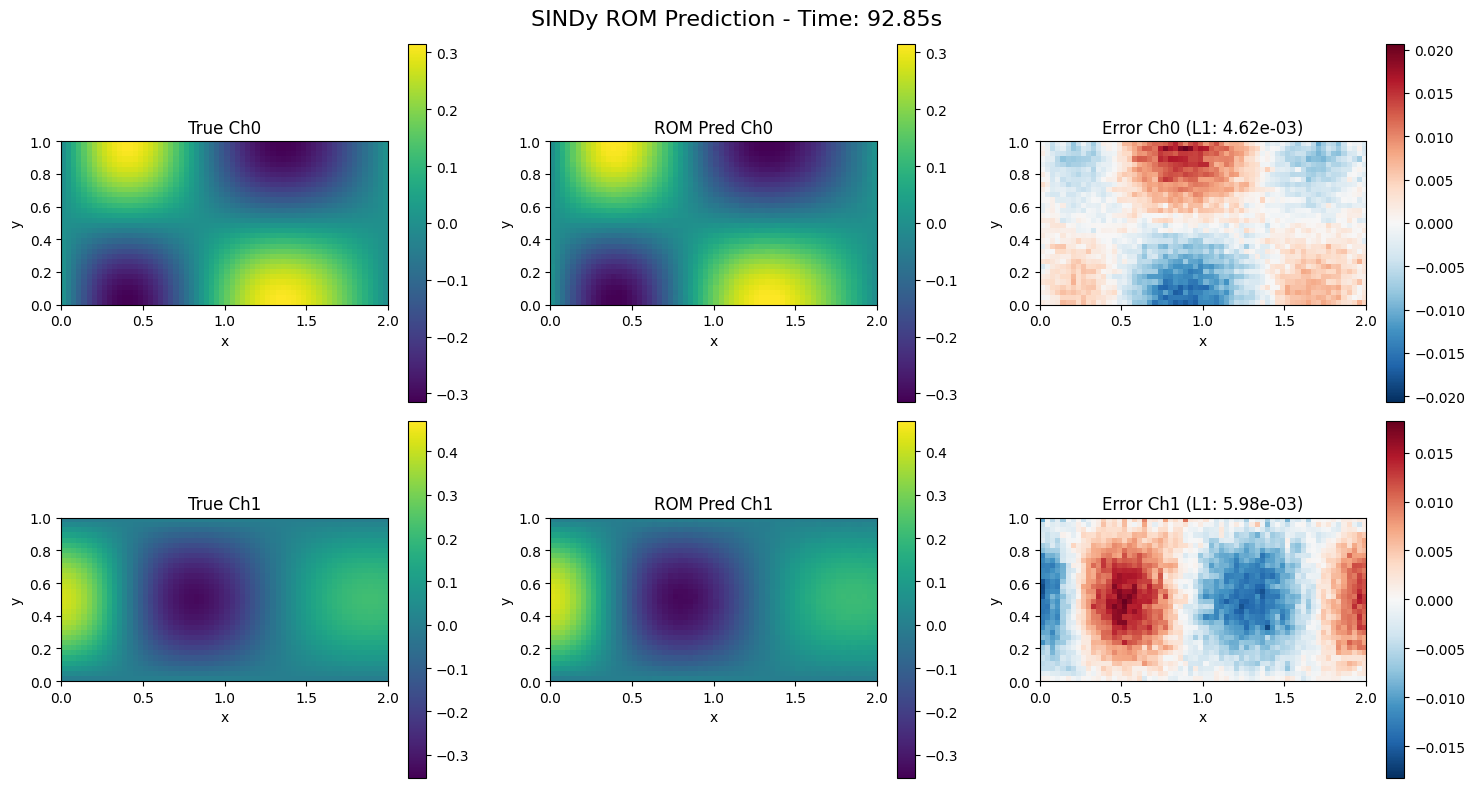

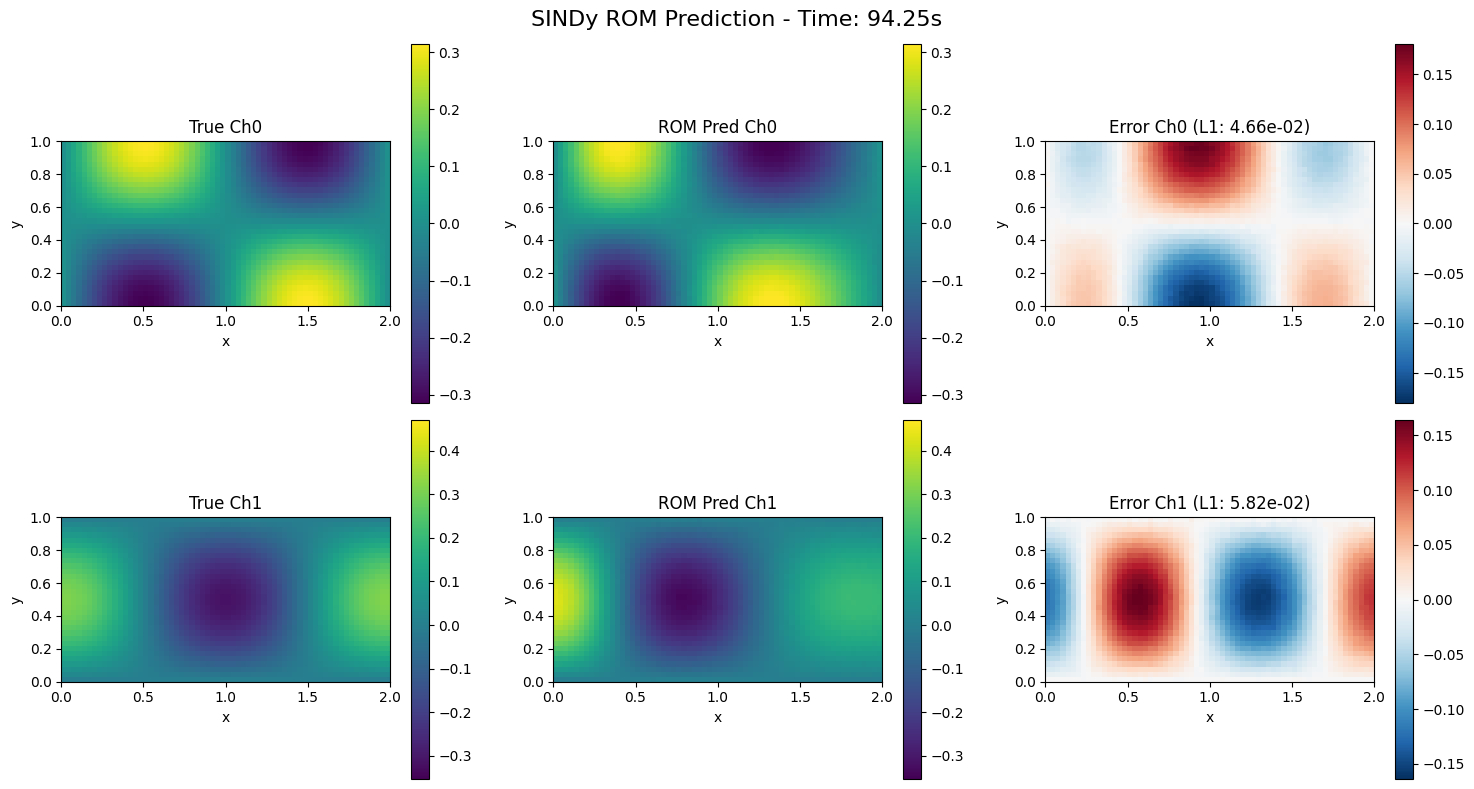

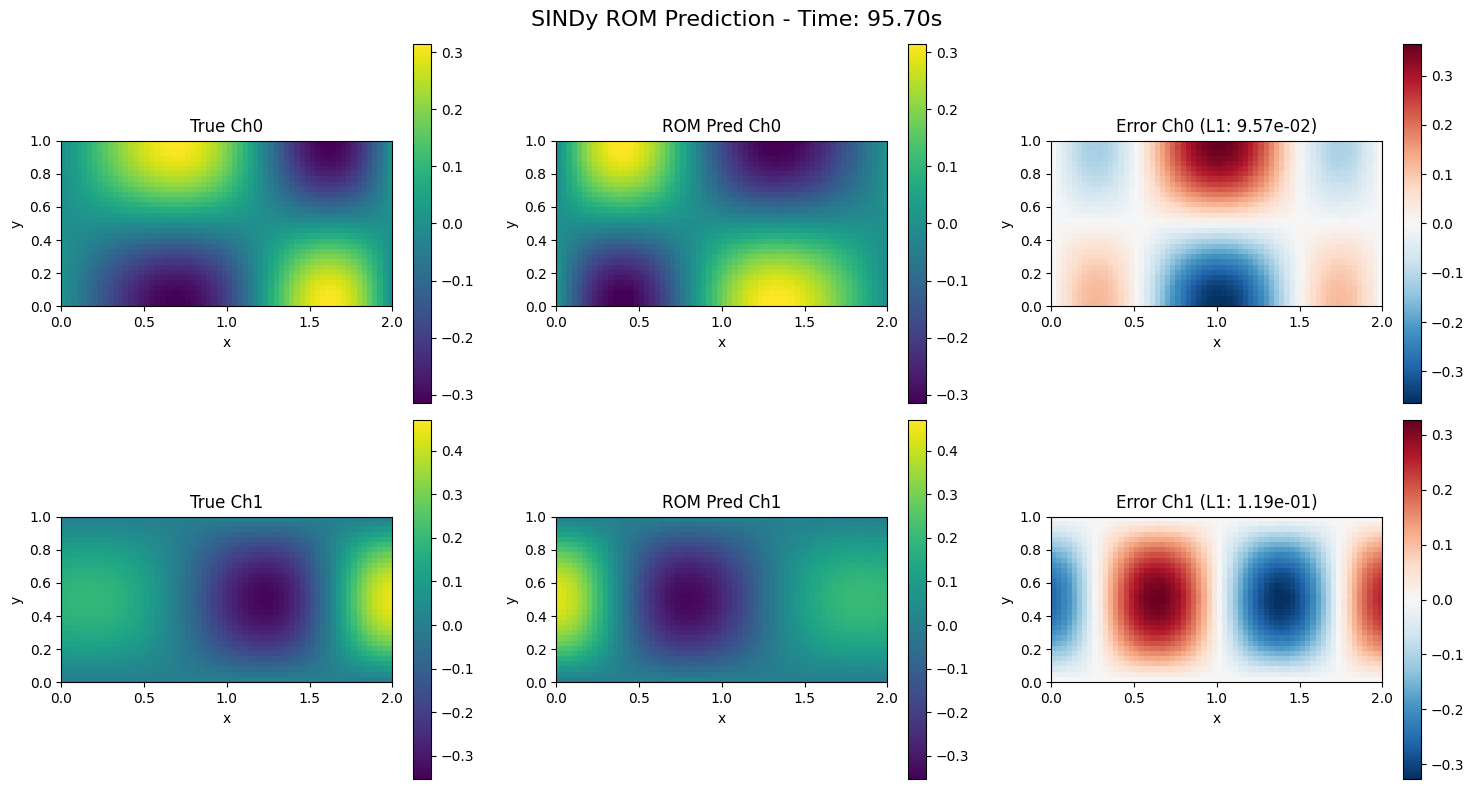

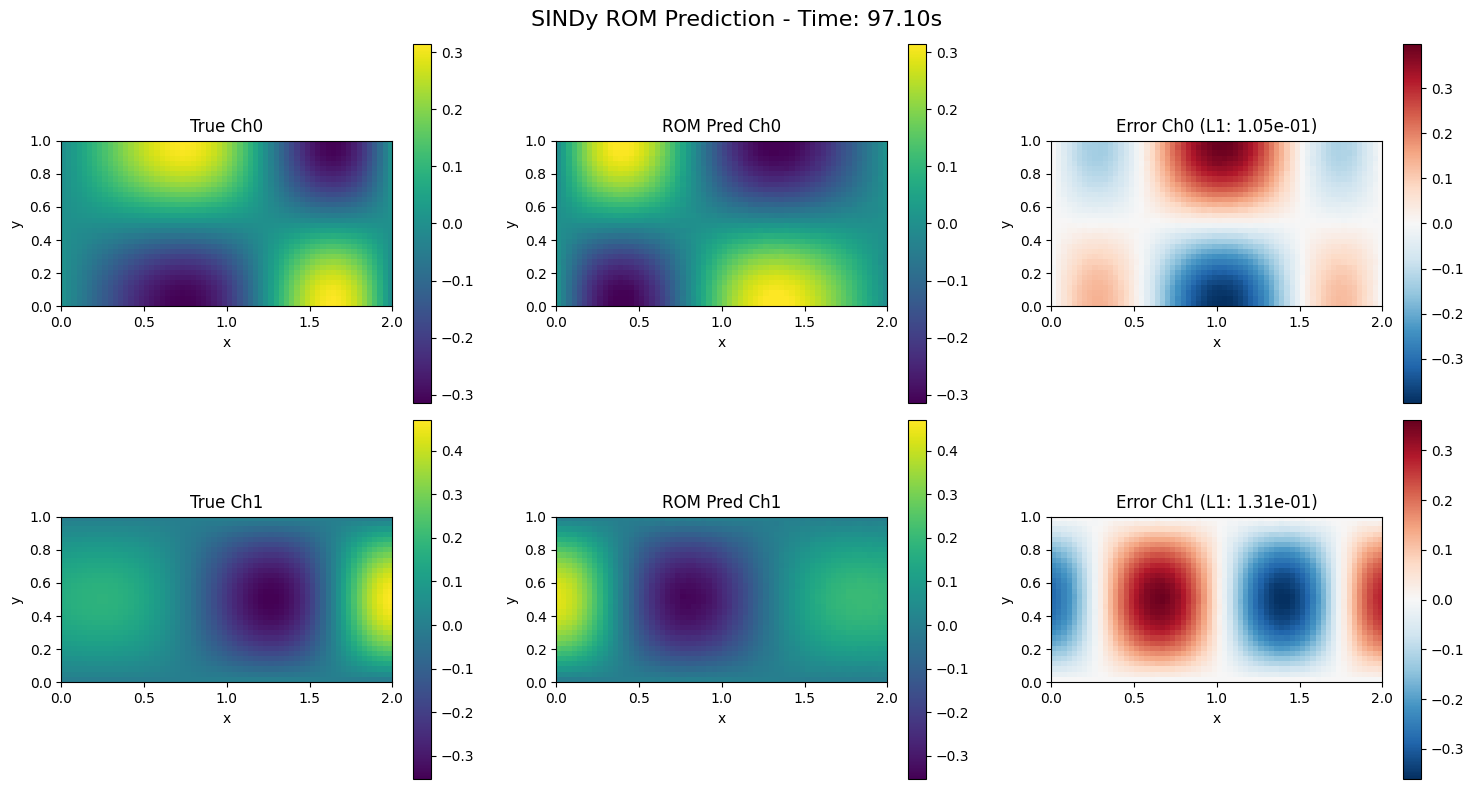

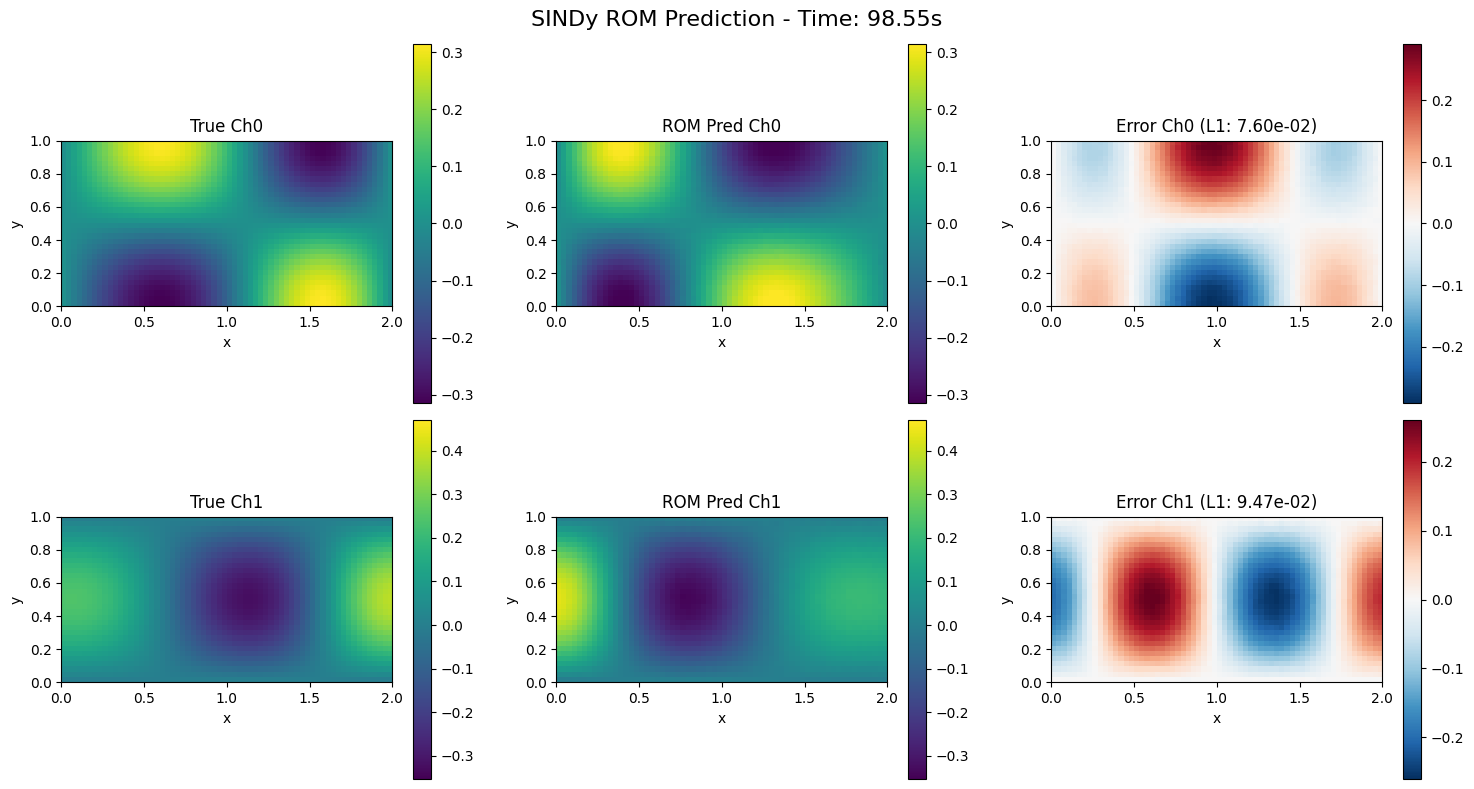

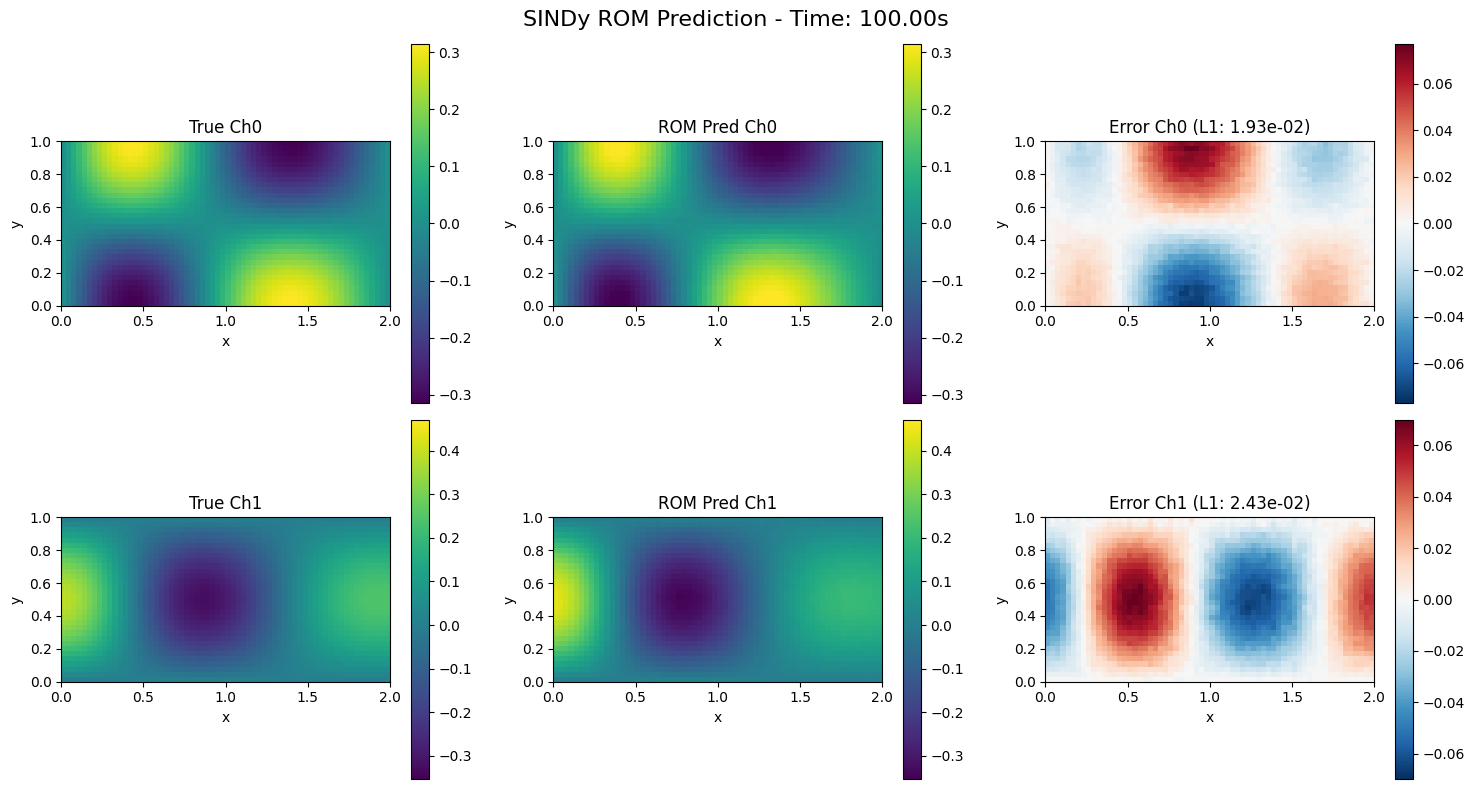

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def validate_rom_from_test_loader(model, test_loader, num_frames_to_show=8):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    # --- 1. RECUPERO DATI DAL TEST_LOADER ---
    all_x_true = []
    all_t_true = []
    
    with torch.no_grad():
        for batch in test_loader:
            x, _, t = batch  # x expected: [B, H, W, C]
            all_x_true.append(x.cpu())
            all_t_true.append(t.cpu())
            
    all_x_true = torch.cat(all_x_true, dim=0) 
    all_t_true = torch.cat(all_t_true, dim=0).numpy()
    n_samples = all_x_true.shape[0]

    # --- 2. CONDIZIONE INIZIALE E CODIFICA ---
    x0 = all_x_true[0:1].to(device) 
    with torch.no_grad():
        z0 = model.encode(x0).cpu().numpy().flatten()

    # --- 3. EVOLUZIONE SINDY ---
    def sindy_dynamics_ode(z_vec, t_val):
        z_tensor = torch.tensor(z_vec.reshape(1, -1), dtype=torch.float32).to(device)
        t_tensor = torch.tensor([t_val], dtype=torch.float32).to(device)
        with torch.no_grad():
            theta = model.construct_sindy_library(z_tensor)
            xi_eff = model.sindy_coeffs * model.sindy_mask
            dzdt = torch.matmul(theta, xi_eff)
        return dzdt.cpu().numpy().flatten()

    z_simulated = odeint(sindy_dynamics_ode, z0, all_t_true)

    # --- 4. DECODIFICA ---
    with torch.no_grad():
        z_sim_tensor = torch.tensor(z_simulated, dtype=torch.float32).to(device)
        x_sim_reconstructed = model.decode(z_sim_tensor).cpu().numpy()

    # --- 5. VISUALIZZAZIONE (2 righe x 3 colonne per snapshot) ---
    indices = np.linspace(0, n_samples - 1, num_frames_to_show, dtype=int)
    plot_extent = [0, 2, 0, 1]

    # Calcolo i limiti globali per canale per avere colorbar coerenti tra snapshot
    v_limits = []
    for c in range(2):
        v_limits.append({
            'min': all_x_true[..., c].min().item(),
            'max': all_x_true[..., c].max().item()
        })

    for idx in indices:
        # Creiamo una figura 2x3 per ogni istante temporale prescelto
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        fig.suptitle(f"SINDy ROM Prediction - Time: {all_t_true[idx]:.2f}s", fontsize=16)

        for c in range(2): # Ciclo sui canali (riga 0 e riga 1)
            img_true = all_x_true[idx, ..., c].numpy().T
            img_sim  = x_sim_reconstructed[idx, ..., c].T
            residual = img_true - img_sim

            # --- Ground Truth ---
            im1 = axes[c, 0].imshow(img_true, cmap='viridis', origin='lower', 
                                   extent=plot_extent, vmin=v_limits[c]['min'], vmax=v_limits[c]['max'])
            axes[c, 0].set_title(f"True Ch{c}")
            plt.colorbar(im1, ax=axes[c, 0])

            # --- Prediction ---
            im2 = axes[c, 1].imshow(img_sim, cmap='viridis', origin='lower', 
                                   extent=plot_extent, vmin=v_limits[c]['min'], vmax=v_limits[c]['max'])
            axes[c, 1].set_title(f"ROM Pred Ch{c}")
            plt.colorbar(im2, ax=axes[c, 1])

            # --- Error (Adaptive) ---
            abs_err_max = max(np.max(np.abs(residual)), 1e-10)
            im3 = axes[c, 2].imshow(residual, cmap='RdBu_r', origin='lower', 
                                   extent=plot_extent, vmin=-abs_err_max, vmax=abs_err_max)
            axes[c, 2].set_title(f"Error Ch{c} (L1: {np.abs(residual).mean():.2e})")
            plt.colorbar(im3, ax=axes[c, 2])

            # Label assi per ogni subplot
            for ax in axes[c]:
                ax.set_xlabel("x")
                ax.set_ylabel("y")

        plt.tight_layout()
        plt.show()

# Esempio di utilizzo:
validate_rom_from_test_loader(model, test_loader)


--- Analysis for timestep t = 94.50 (Index 90) ---
Component U:
  > L1 Absolute Error: 1.40100e-01
  > L1 Relative Error: 89.68%
Component V:
  > L1 Absolute Error: 1.58435e-01
  > L1 Relative Error: 98.11%


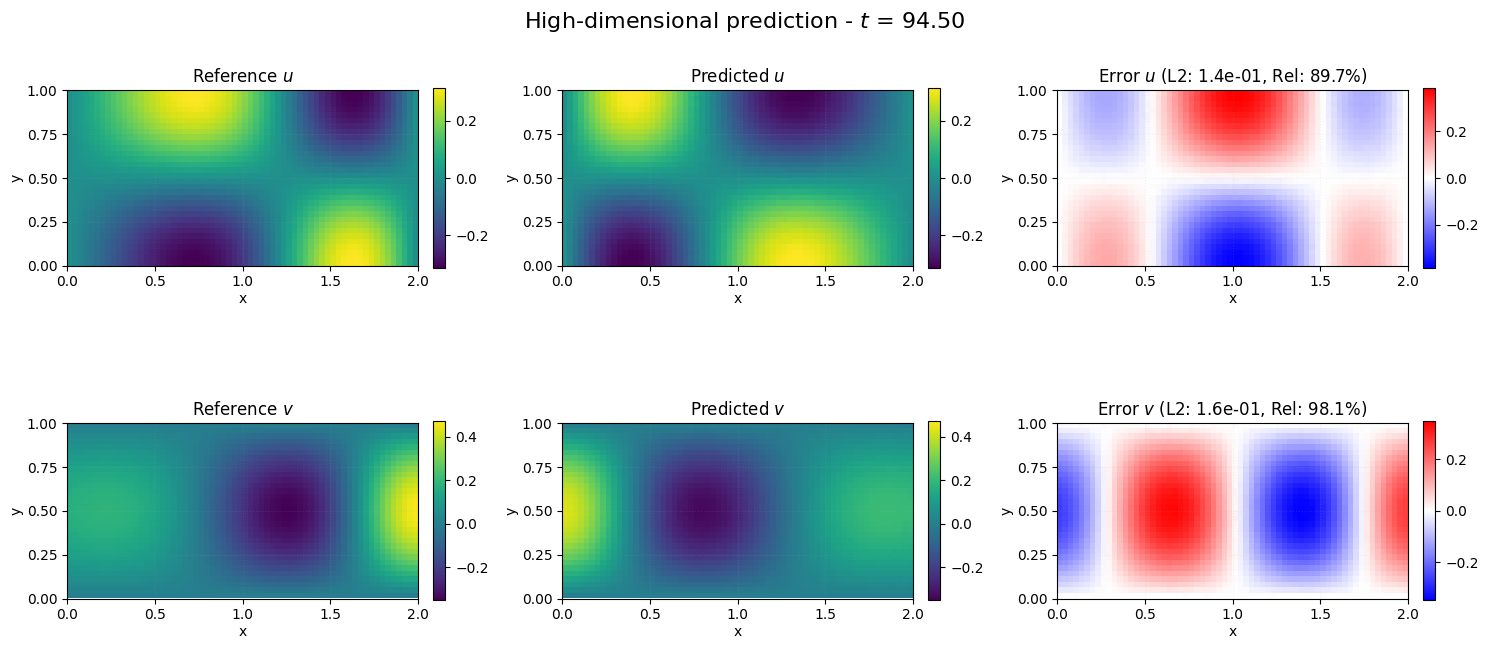


--- Analysis for timestep t = 97.50 (Index 150) ---
Component U:
  > L1 Absolute Error: 1.84748e-02
  > L1 Relative Error: 11.71%
Component V:
  > L1 Absolute Error: 2.13432e-02
  > L1 Relative Error: 13.55%


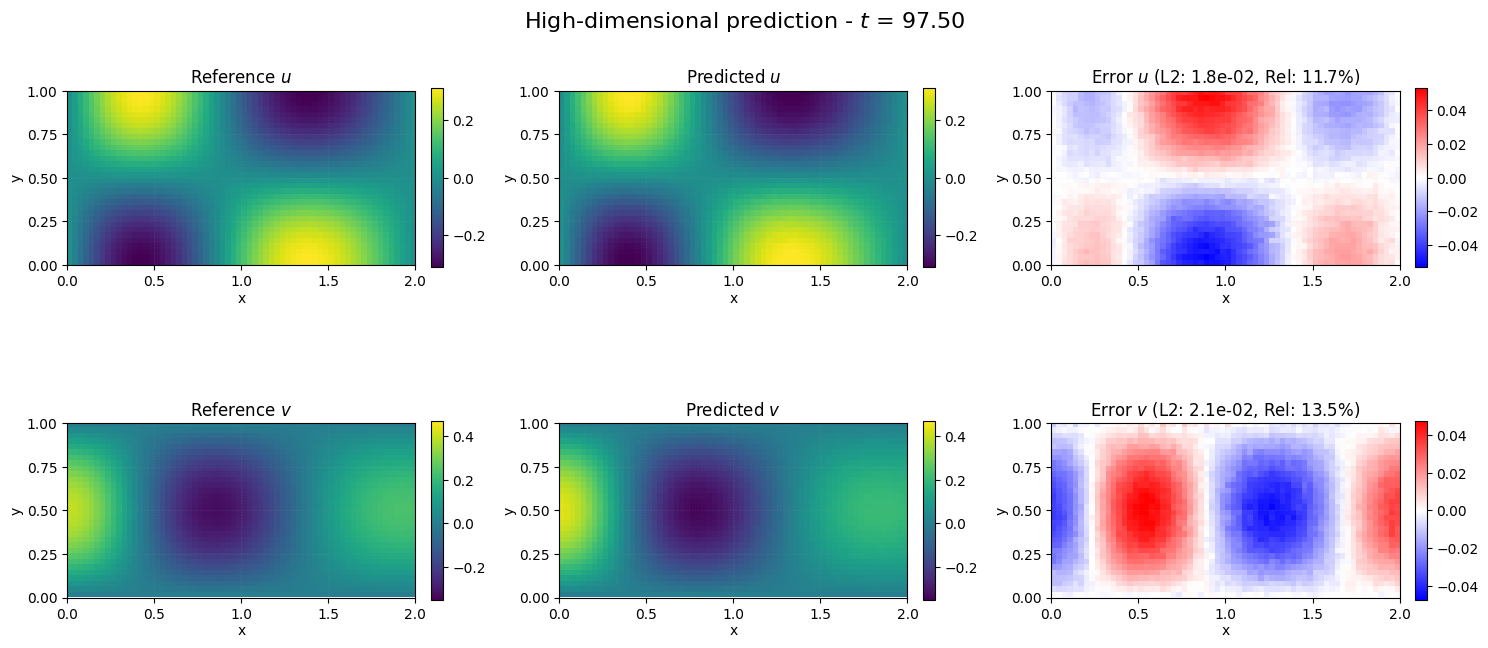


--- Analysis for timestep t = 99.25 (Index 185) ---
Component U:
  > L1 Absolute Error: 5.53654e-02
  > L1 Relative Error: 34.99%
Component V:
  > L1 Absolute Error: 6.28238e-02
  > L1 Relative Error: 40.30%


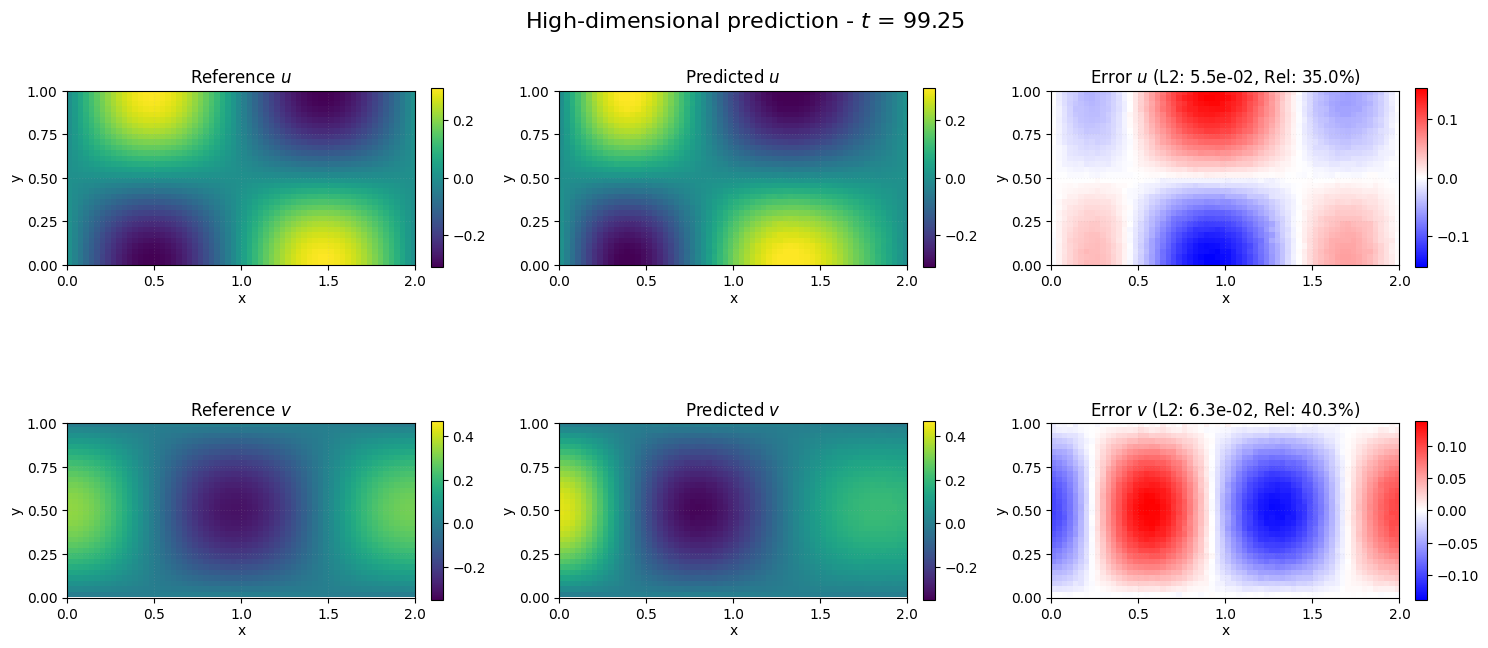

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap
import os 

def validate_rom_from_test_loader(model, test_loader, target_indices=None, save_path=None):
    # --- FIX: corretto torch.cuda.is_available() ---
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    # --- Definizione Colormap Custom (Blue-White-Red) ---
    custom_bwr = LinearSegmentedColormap.from_list("custom_bwr", ["blue", "white", "red"])

    # --- 1. RECUPERO DATI DAL TEST_LOADER ---
    all_x_true = []
    all_t_true = []
    
    with torch.no_grad():
        for batch in test_loader:
            x, _, t = batch  
            all_x_true.append(x.cpu())
            all_t_true.append(t.cpu())
            
    all_x_true = torch.cat(all_x_true, dim=0) 
    all_t_true = torch.cat(all_t_true, dim=0).numpy()
    n_samples = all_x_true.shape[0]

    # --- 2. GESTIONE INDICI TARGET ---
    if target_indices is None:
        indices = np.linspace(0, n_samples - 1, 3, dtype=int)
    elif isinstance(target_indices, int):
        indices = [target_indices]
    else:
        indices = target_indices

    # --- 3. CONDIZIONE INIZIALE E SIMULAZIONE ---
    x0 = all_x_true[0:1].to(device) 
    with torch.no_grad():
        z0 = model.encode(x0).cpu().numpy().flatten()

    def sindy_dynamics_ode(z_vec, t_val):
        z_tensor = torch.tensor(z_vec.reshape(1, -1), dtype=torch.float32).to(device)
        with torch.no_grad():
            theta = model.construct_sindy_library(z_tensor)
            xi_eff = model.sindy_coeffs * model.sindy_mask
            dzdt = torch.matmul(theta, xi_eff)
        return dzdt.cpu().numpy().flatten()

    z_simulated = odeint(sindy_dynamics_ode, z0, all_t_true)

    with torch.no_grad():
        z_sim_tensor = torch.tensor(z_simulated, dtype=torch.float32).to(device)
        x_sim_reconstructed = model.decode(z_sim_tensor).cpu().numpy()

    # --- 4. VISUALIZZAZIONE E CALCOLO ERRORI ---
    plot_extent = [0, 2, 0, 1]
    channel_names = ["u", "v"]

    v_limits = []
    for c in range(2):
        v_limits.append({
            'min': all_x_true[..., c].min().item(),
            'max': all_x_true[..., c].max().item()
        })

    for idx in indices:
        if idx >= n_samples: continue

        print(f"\n--- Analysis for timestep t = {all_t_true[idx]:.2f} (Index {idx}) ---")
        fig, axes = plt.subplots(2, 3, figsize=(15, 7))
        fig.suptitle(f"High-dimensional prediction - $t$ = {all_t_true[idx]:.2f}", 
                      fontsize=16, y=0.92)

        for c in range(2): 
            img_true = all_x_true[idx, ..., c].numpy().T
            img_sim  = x_sim_reconstructed[idx, ..., c].T
            residual = img_true - img_sim
            
            # --- CALCOLO ERRORI ---
            l2_abs = np.linalg.norm(residual) / np.sqrt(residual.size)
            l2_ref = np.linalg.norm(img_true) / np.sqrt(img_true.size)
            l2_rel_perc = (l2_abs / (l2_ref + 1e-12)) * 100
            
            # Stampa a video di entrambi gli errori
            print(f"Component {channel_names[c].upper()}:")
            print(f"  > L1 Absolute Error: {l2_abs:.5e}")
            print(f"  > L1 Relative Error: {l2_rel_perc:.2f}%")

            cbar_kwargs = {'fraction': 0.046, 'pad': 0.04, 'shrink': 0.7, 'aspect': 15}

            # Plot True
            im1 = axes[c, 0].imshow(img_true, cmap='viridis', origin='lower', 
                                    extent=plot_extent, vmin=v_limits[c]['min'], vmax=v_limits[c]['max'])
            axes[c, 0].set_title(f"Reference ${channel_names[c]}$", pad=6)
            plt.colorbar(im1, ax=axes[c, 0], **cbar_kwargs)

            # Plot Pred
            im2 = axes[c, 1].imshow(img_sim, cmap='viridis', origin='lower', 
                                    extent=plot_extent, vmin=v_limits[c]['min'], vmax=v_limits[c]['max'])
            axes[c, 1].set_title(f"Predicted ${channel_names[c]}$", pad=6)
            plt.colorbar(im2, ax=axes[c, 1], **cbar_kwargs)

            # Plot Error
            abs_err_max = max(np.max(np.abs(residual)), 1e-10)
            im3 = axes[c, 2].imshow(residual, cmap=custom_bwr, origin='lower', 
                                    extent=plot_extent, vmin=-abs_err_max, vmax=abs_err_max)
            
            # Titolo del subplot con L1 e Relativo
            axes[c, 2].set_title(f"Error ${channel_names[c]}$ (L2: {l2_abs:.1e}, Rel: {l2_rel_perc:.1f}%)", pad=6) # fontsize=10)
            plt.colorbar(im3, ax=axes[c, 2], **cbar_kwargs)

            for ax in axes[c]:
                ax.set_xlabel("x", labelpad=2); ax.set_ylabel("y", labelpad=2)
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
                ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
                ax.grid(alpha=0.15, linestyle=':')

        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.subplots_adjust(hspace=0.3)

        if save_path:
            if not os.path.exists(save_path): os.makedirs(save_path)
            file_name = f"prediction_idx_{idx}.png"
            plt.savefig(os.path.join(save_path, file_name), dpi=300, bbox_inches='tight')

        plt.show()

# Esempio di chiamata
validate_rom_from_test_loader(model, test_loader, target_indices=[90, 150, 185], save_path='.')